<a id="chapter-07"></a>

# Chapter 07 · Higher-Level RL Libraries / 高层 RL 库

[← 学习索引](../README.md) · [项目主页](../../README.md) · [跳到本章扩展](#extension)

> 学习方式：按顺序读到代码单元，先预测输出再运行。正文只保留理解主线；非必要的证明、变体与工程细节放在[扩展](#extension)。

**学完本章，你应该能：**

- 理解 selector、agent、experience source、replay buffer 的职责
- 掌握 n-step experience
- 能把 PTAN 抽象映射回普通 Python

**开始前最好已经会：**

- 理解 DQN 的 transition 与 target network
- 知道 Python iterator 和 dataclass
- 理解 n-step return 的目的


## 原书覆盖地图

| 原书主题 | 本 notebook 对应位置 | 深度 |
|---|---|---|
| Why RL libraries? | 组件化动机 | 详细 |
| PTAN action selectors / agents | 数据流与源码路线 | 详细 |
| Experience sources / first-last | n-step 推导与实验 | 详细 |
| Replay buffers / TargetNet / Ignite helpers | 组件职责表 | 详细 |
| PTAN CartPole solver | 端到端伪代码与源码 | 完整 |
| Other RL libraries | 扩展 | 概览 |

“详细”表示正文包含推导或完整数据流；“源码路线”表示正文解释职责并链接真实实现；次要变体保留在扩展区。这样可以明确看到本章没有把原书哪个主题悄悄跳过。


## 0. 先想一个问题

完整 RL 代码为什么容易写成几百行？因为动作选择、环境交互、经验拼接、回放和训练纠缠在一起。高层库的核心价值是把这些职责拆开。

> 不必立刻回答。读完本章后再回到这里，尝试用两三句话作答。


## 1. 心智模型：先知道信息怎样流动

库的价值不是隐藏算法，而是稳定地处理动作选择、环境交互、episode 边界、回放采样和 target 同步。

学习时始终追问三件事：**当前已知什么？要估计什么？哪个量会被更新？** 这比先背算法名称更重要。


## 2. 符号表：先统一语言

| 符号/名称 | 含义 | 阅读时怎么想 |
|---|---|---|
| selector | 把分数变成动作 | argmax、epsilon-greedy、概率采样 |
| agent | 观测到动作的可调用对象 | 组合网络与 selector |
| experience source | 驱动环境并产生经验 | 负责 episode 边界 |
| replay buffer | 保存并随机采样经验 | 训练数据仓库 |
| target net | 在线/目标网络管理器 | 同步或 soft update |

第一次阅读只需认识这些符号；看到公式时再回来查，不要求一次背完。


## 3. 分步推导：公式不是凭空出现的


### 1. n-step return 从哪里来

反复展开 $G_t=R_{t+1}+\gamma G_{t+1}$：

$$G_t=R_{t+1}+\gamma R_{t+2}+\cdots+\gamma^{n-1}R_{t+n}+\gamma^nG_{t+n}$$

把最后未知的真实回报替换成价值估计，得到 n-step target：

$$y_t=\sum_{k=0}^{n-1}\gamma^kR_{t+k+1}+\gamma^nV(S_{t+n})$$

若中途真正终止，最后一项消失，而且实际 $n$ 可能小于设定值。

### 2. 为什么要拆成组件

数据流可以写成：

```text
observation → agent → action → environment
     ↑                         ↓
     └──── experience source ← transition
                    ↓
              replay buffer → trainer
```

每个组件只有一个主要变化原因，便于单独测试。高层库不是替你理解算法，而是把已经理解的重复工程模式封装起来。


## 4. 手算一个最小例子


奖励 `[1,0,2]`、$\gamma=0.9$ 的 3-step reward 为
$1+0.9\times0+0.9^2\times2=2.62$。

若第 3 步后未终止且 $V(S_{t+3})=4$，target 还要加 $0.9^3\times4=2.916$，总计 5.536。若第 3 步终止，则不加。


> 手算的目的不是练算术，而是给公式建立可检查的直觉。代码输出与手算矛盾时，先停下来找原因。


## 5. 本章公式卡


### n-step transition

$$R_t^{(n)}=\sum_{k=0}^{n-1}\gamma^kR_{t+k+1}$$

若中途未终止：$y_t=R_t^{(n)}+\gamma^nV(S_{t+n})$；若已终止，则不再 bootstrap。一个经验对象至少需要 `(state, action, reward, last_state)`，其中 `last_state=None` 可清楚表示真正终止。


这张卡用于复习，不替代上一节的推导。


## 6. 公式 ↔ 代码逐项对照

| 数学对象/步骤 | 代码对应 | 作用与形状提示 |
|---|---|---|
| $\pi$ 或 $Q$ | agent 内的 model | 把 observation 变成 logits/Q |
| 动作选择规则 | selector | 网络输出到具体动作 |
| $(s,a,r,s')$ | `Experience` | 跨组件传递的最小数据结构 |
| $R_t^{(n)}$ | `n_step_return(rewards, gamma)` | 折扣奖励前缀 |
| 终止 | `last_state is None` | 清楚表达禁止 bootstrap |
| $\theta^-$ | `TargetNet` | 管理目标参数同步 |

**从公式过渡到代码时：**用一个纯 Python 函数构造 n-step 回报，先理解数据语义，再阅读 PTAN 的封装。


## 7. 动手实验

运行前先做三件事：

1. 根据手算例子预测关键输出的方向或数量级；
2. 找到上一张表中的每个代码变量；
3. 运行后只改一个变量，观察结果是否符合公式。


In [1]:
from dataclasses import dataclass

@dataclass(frozen=True)
class Experience:
    state: int
    action: int
    reward: float
    last_state: int | None

def n_step_return(rewards, gamma=0.9):
    return sum((gamma ** k) * r for k, r in enumerate(rewards))

exp = Experience(state=2, action=1, reward=n_step_return([1, 0, 2]), last_state=5)
print(exp)
print("bootstrap discount gamma^3 =", 0.9 ** 3)


Experience(state=2, action=1, reward=2.62, last_state=5)
bootstrap discount gamma^3 = 0.7290000000000001


### 怎样读运行结果

示例 `Experience` 是不可变数据对象，方便排查谁修改了经验。注意 `reward` 已经可以是 n-step 聚合值，此时 bootstrap 必须使用 $\gamma^n$ 而不是 $\gamma$。

如果结果不符合描述，先检查随机种子、终止 mask、数组 shape 和依赖版本，而不是马上调超参数。


## 8. 完整算法：把前面的零件装起来


```text
selector = EpsilonGreedyActionSelector(epsilon)
agent = DQNAgent(net, selector)
exp_source = ExperienceSourceFirstLast(env, agent, gamma, steps_count=n)
buffer = ExperienceReplayBuffer(exp_source, capacity)
target_net = TargetNet(net)
repeat:
    buffer.populate(1)
    若 buffer 太小：continue
    batch = buffer.sample(B)
    states, actions, rewards, last_states = unpack(batch)
    计算 n-step DQN loss
    更新 online net；周期同步 target_net
```


## 9. 第二个验证实验

第一个实验负责建立直觉；下面这个实验专门验证一个容易写错的性质。它仍然保持轻量，目的是让你能用断言判断实现是否符合公式。


In [2]:
def n_step_target(rewards, gamma, bootstrap=None):
    total = sum((gamma ** i) * r for i, r in enumerate(rewards))
    if bootstrap is not None:
        total += (gamma ** len(rewards)) * bootstrap
    return total

print("terminated:", n_step_target([1, 0, 2], 0.9, bootstrap=None))
print("non-terminal:", n_step_target([1, 0, 2], 0.9, bootstrap=4.0))
assert abs(n_step_target([1, 0, 2], 0.9) - 2.62) < 1e-9


terminated: 2.62
non-terminal: 5.5360000000000005


## 10. 项目源码精读路线

| 文件 | 重点类/函数 | 阅读目的 |
|---|---|---|
| [`01_actions.py`](../../Chapter07/01_actions.py) | action selectors | 从分数到动作 |
| [`02_agents.py`](../../Chapter07/02_agents.py) | `DQNNet`, `PolicyNet` 与 agent | 从观测到动作分数 |
| [`03_exp_sources.py`](../../Chapter07/03_exp_sources.py) | experience source 示例 | 环境驱动和 n-step 拼接 |
| [`04_replay_buf.py`](../../Chapter07/04_replay_buf.py) | replay buffer | 存储与随机采样 |
| [`05_target_net.py`](../../Chapter07/05_target_net.py) | TargetNet | 同步语义 |
| [`06_cartpole.py`](../../Chapter07/06_cartpole.py) | `unpack_batch` 与训练循环 | 把组件装回完整 DQN |

<details>
<summary>为什么按这个顺序读</summary>

用 `Chapter07/lib.py` 的 `ToyEnv` 和 `DullAgent` 先观察 experience source 的边界行为，因为真实 CartPole 会掩盖数据错误。重点打印 `ExperienceFirstLast.reward` 是否已包含 n-step 折扣和 `last_state=None` 是否只用于自然终止。进入 solver 后，`unpack_batch` 必须使用 $\gamma^n$ bootstrap。

</details>

notebook 的实验负责隔离原理，仓库脚本负责完整环境、日志和训练。阅读时拿着第 6 节对照表寻找同一数学对象；变量名可以不同，数据语义不能不同。


## 11. 训练曲线、调参与失败复盘

**本章主诊断指标：**1-step 与 3-step Q-learning 的回报传播速度

下面的曲线来自可重复运行的微型训练，不是手工填写的数据。它用于学习“该看什么、怎样判断”；原书规模的训练应使用上一节链接的项目脚本，并同时保存配置、随机种子、环境步数和 wall-clock。

> 曲线阅读顺序：先看任务指标，再看优化指标，最后看资源指标。单次最好成绩不能代替多随机种子均值与波动。


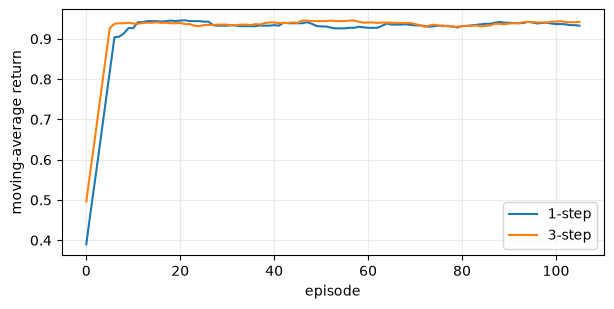

final means: 0.933 0.942


In [3]:
import numpy as np
import matplotlib.pyplot as plt

def plot_curve(series, title, ylabel, *, window=1):
    # Plot raw measurements and an optional moving average.
    values = np.asarray(series, dtype=float)
    x = np.arange(1, len(values) + 1)
    plt.figure(figsize=(7, 3.2))
    plt.plot(x, values, alpha=0.35, label="raw")
    if window > 1 and len(values) >= window:
        smooth = np.convolve(values, np.ones(window) / window, mode="valid")
        plt.plot(x[window - 1:], smooth, linewidth=2, label=f"MA({window})")
    plt.title(title)
    plt.xlabel("iteration / episode")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()
    plt.close()


rng = np.random.default_rng(7)

def train(n_steps):
    q = np.zeros((7, 2)); history = []
    for episode in range(120):
        s, trajectory, total = 0, [], 0.0
        for _ in range(35):
            a = rng.integers(2) if rng.random() < 0.2 else np.argmax(q[s])
            ns = max(0, s - 1) if a == 0 else min(6, s + 1)
            r, done = (1.0 if ns == 6 else -0.01), ns == 6
            trajectory.append((s, a, r)); total += r; s = ns
            if done: break
        for t, (state, action, _) in enumerate(trajectory):
            end = min(t + n_steps, len(trajectory))
            ret = sum((0.95 ** (k - t)) * trajectory[k][2] for k in range(t, end))
            if end < len(trajectory): ret += 0.95 ** (end - t) * q[trajectory[end][0]].max()
            q[state, action] += 0.2 * (ret - q[state, action])
        history.append(total)
    return np.convolve(history, np.ones(15) / 15, mode="valid")

one, three = train(1), train(3)
plt.figure(figsize=(7, 3.2)); plt.plot(one, label="1-step"); plt.plot(three, label="3-step")
plt.xlabel("episode"); plt.ylabel("moving-average return"); plt.grid(alpha=.25); plt.legend(); plt.show(); plt.close()
print("final means:", round(one[-1], 3), round(three[-1], 3))


### 曲线怎么读

3-step 往往更快把终点奖励传回早期状态，但曲线也可能更抖。重点不是宣称 3-step 永远更好，而是理解传播速度与方差的交换。

### 调参过程：一次只改变一个因素

- 先保持 action selector、agent、buffer 不变，只改 `steps_count`。
- 比较 1、3、5 step 的多随机种子均值和方差。
- 记得把 bootstrap 折扣改为 $\gamma^n$，否则比较无效。

### 失败案例复盘

- 改了 n-step 却仍乘单步 $\gamma$。
- episode 截断后错误地从下一局 bootstrap。
- PTAN experience 字段顺序理解错误，state/last_state 对调。

遇到失败时先保存配置和原始曲线，复现后再修；不要一边改环境、一边改网络、一边改学习率，否则无法知道修复来自哪里。


## 12. 实用技巧与常见坑

- 先追踪一个 episode 的经验对象，再追踪 batch；这样最容易发现边界错误。
- 库版本变化时先检查构造器签名，不要照抄旧教程。
- 抽象层越高，越要用 shape 和终止语义的单元测试兜底。

这些不是附属知识：RL 结果方差大，很多“算法没学会”其实是终止语义、shape、数据泄漏或评估方式错误。


## 13. 动手练习

修改函数，使它同时返回累积回报和实际步数；说明提前终止时如何选择 bootstrap 折扣。

<details>
<summary>完成标准（做完再展开）</summary>

不只给出结果；还应说明改了哪个变量、对应哪条公式、变化是否符合预期，并写出至少一个边界情况。若能用 `assert` 固化结论更好。
</details>


## 14. 练习参考答案

<details>
<summary>完成练习后再展开</summary>

让函数返回 `(total, len(rewards))`。提前终止时 `bootstrap=None`；未终止时使用 `gamma ** actual_steps`，不是固定使用设定的 n，因为 episode 边界或数据切片可能让实际步数更短。

</details>


## 15. 合上 notebook 后，脑中应留下什么

- 高层库拆分工程职责，不改变算法数学。
- n-step return 来自反复展开一步回报递归。
- 终止状态要在经验表示中无歧义。
- 先理解纯 Python 数据流，再使用 PTAN 等库。

回到开头的那个问题。现在请不用公式，向一个没学过本章的人解释答案；能讲清楚，才算真正理解。


## 16. 两分钟自测

**问题：**3-step experience 为什么 bootstrap 要乘 $\gamma^3$？若第 2 步提前终止怎么办？

<details>
<summary>展开答案</summary>

因为从当前时刻到 bootstrap 状态跨了 3 次折扣。若第 2 步终止，只累计实际两步奖励，不再 bootstrap，并记录真实步数或用 `last_state=None`。
</details>


## 17. 与前后章节连接

第 8 章继续使用同一 PTAN 数据管线，只替换 loss、模型或 buffer；这正体现组件化的价值。

学习强化学习最怕把算法记成孤岛。每章结束时，都应能说明本章复用了前面的什么，又为后面准备了什么。


<a id="extension"></a>

## 扩展：主线学完后再深挖

Stable-Baselines3、TorchRL、Ray RLlib 的抽象层和适用规模不同；学习阶段建议至少手写一次核心 loss。

扩展内容用于建立知识地图，不要求第一次学习就掌握。先确保能完成上面的两分钟自测，再决定是否继续。

[↑ 回到开头](#chapter-07) · [← 学习索引](../README.md)
